In [3]:
import pandas as pd
import numpy as np
import pylab as plt

import pypsa

# Import the public function from the package you completed
from energy_model import model_run

# 1. Testing

We are now ready to start running our model from this interface notebook. 

The first thing we want to do is to test whether our `energy_model` module works. We test this by doing a base run, which should exactly reproduce the last outputs from `practical.ipynb`.

In case you get errors, you should try to go back to `preprocessing.py` and/or `model.py` and debug them. Once you idendified and fixed the bugs in the .py files, save them, then come back here, restart the kernel (IMPORTANT, otherwise jupyter will not know the .py files have been modified!!), and try again. 

## 1.1 Default parameters

It's handy to define a series of default parameters to quickly call our `model_run()` function. 

In [4]:
# Default parameters for testing

# input database folder
db_dir = 'input_databases/default'
db_dir_2 = 'input_databases/ff_prices'

# model years
years = [2020,2030,2040,2050]

# intra-year temporal resolution
t_res = 15 # hours

# discount rates
rt = 0.07 # technical discount rate
rs = 0.01 # social discount rate

# passenger cars conversion factor
passenger_cars_cf = 40*0.1  # km/h


## 1.2 Base run

A base run with the new setup looks like this:

In [5]:
base = model_run(db_dir,years,t_res,passenger_cars_cf,rt,rs)
# TIP: You can give your scenario a name, which comes in handy when you need to retrieve
# the scenario name as a string programmatically (e.g. to use as a plot title)
base.name = 'base'

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 578.37it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-_ri76jpt.lp
Reading time = 0.18 seconds
obj: 134936 rows, 61352 columns, 272011 nonzeros
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal


Note that now we only get a very minimalistic output log from pypsa and gurobi, plus the print-out of the status messages that we coded at the end of the `model_run()` function. The full log is stored in results/solver_run.log. Every time you run the model, the new log will be added at the bottom of this file (so it will preserve all your model runs history). 

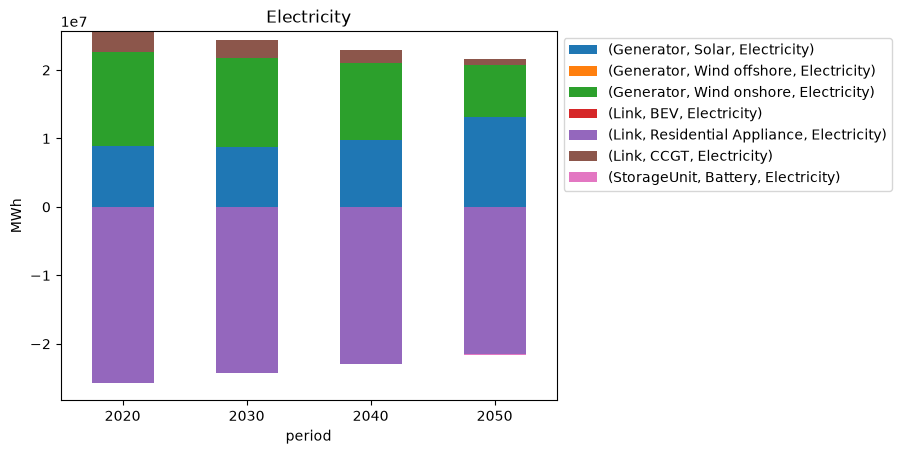

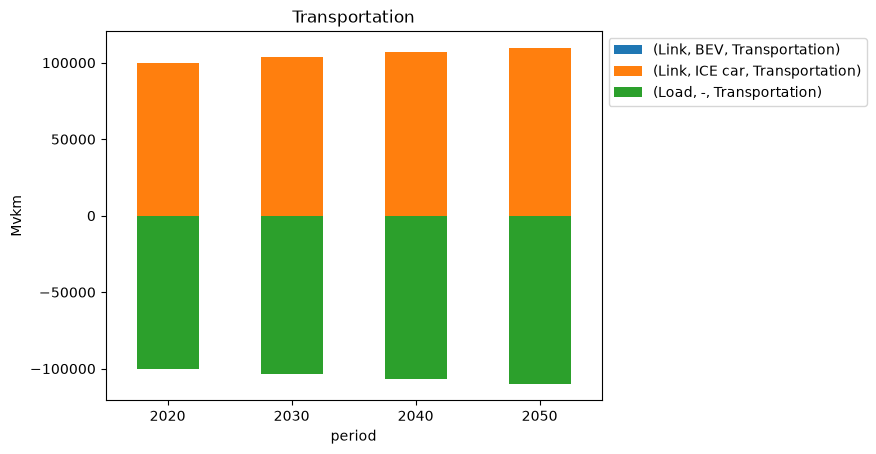

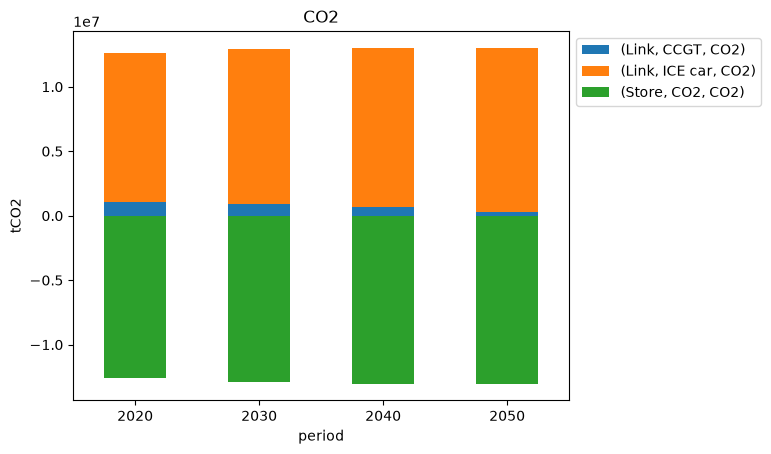

In [6]:
# Let's have a quick look at some of the energy balances 
# (these should look the same as those you had at the end of practical.ipynb):

for c in ['Electricity','Transportation','CO2']: 
    base.statistics.energy_balance(bus_carrier=c).T.plot(kind='bar',stacked='True', rot=0)
    if c=='CO2':
        plt.ylabel('tCO2')
    elif c=='Transportation':
        plt.ylabel('Mvkm')
    else:
        plt.ylabel('MWh')
    plt.legend(bbox_to_anchor=(1,1))
    plt.title(c)

# 2. Individual homework assignment: 

## 2.1 Fossil fuel prices

Open the default input database and modify the right table therein, assigning a price to gas going from 20 €/MWh_th in 2020 to 50 €/MWh_th in 2050, and a gasoline price from 200 to 500 €/MWh_th, respectively, in the same years. 

Rerun the model and check how the three energy balances above have changed: 
- Make a plot comparing the three energy balances in the original base scenario and in the new fossil-fuel price scenario;
- Write a short paragraph on the changes you observe and how they are caused by the changes you made in the input database. 

Our *default* input database now contains fossil fuel prices: in the following assignments continue working with these fossil fuel prices. 

In [7]:
### YOUR CODE HERE ###
# New scenario with fossil fuels prices
m_ffprices = model_run(db_dir_2, years,t_res,passenger_cars_cf,rt,rs)
m_ffprices.name = 'Model: fossil fuels prices'
###

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 549.63it/s]

Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31


Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-0_jw192j.lp
Reading time = 0.18 seconds
obj: 134936 rows, 61352 columns, 272011 nonzeros
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal


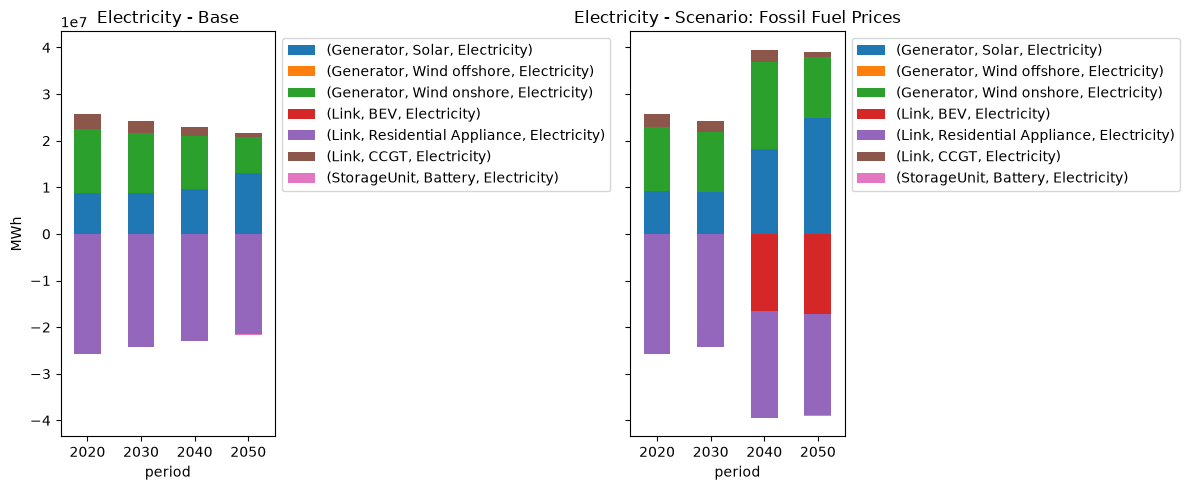

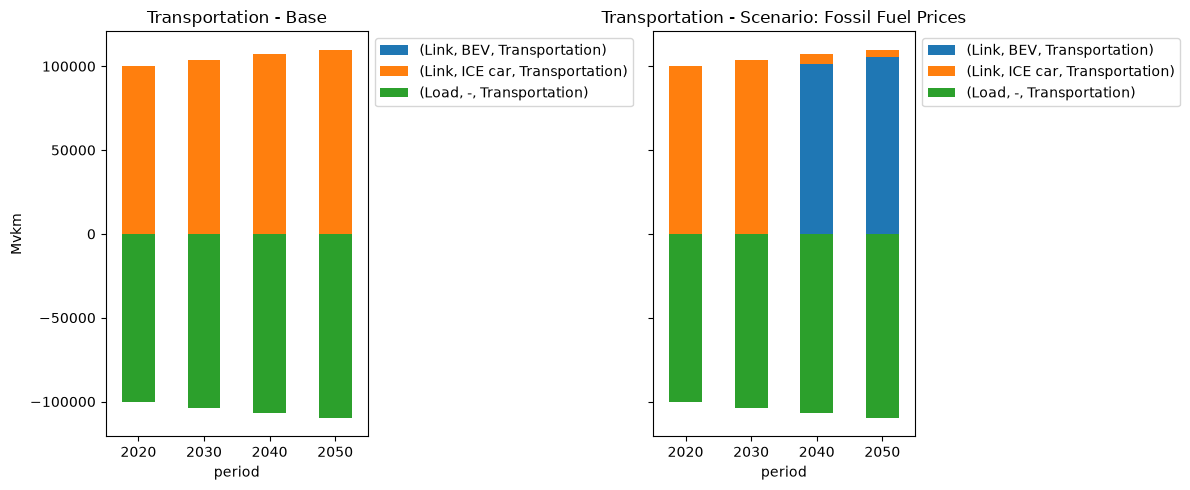

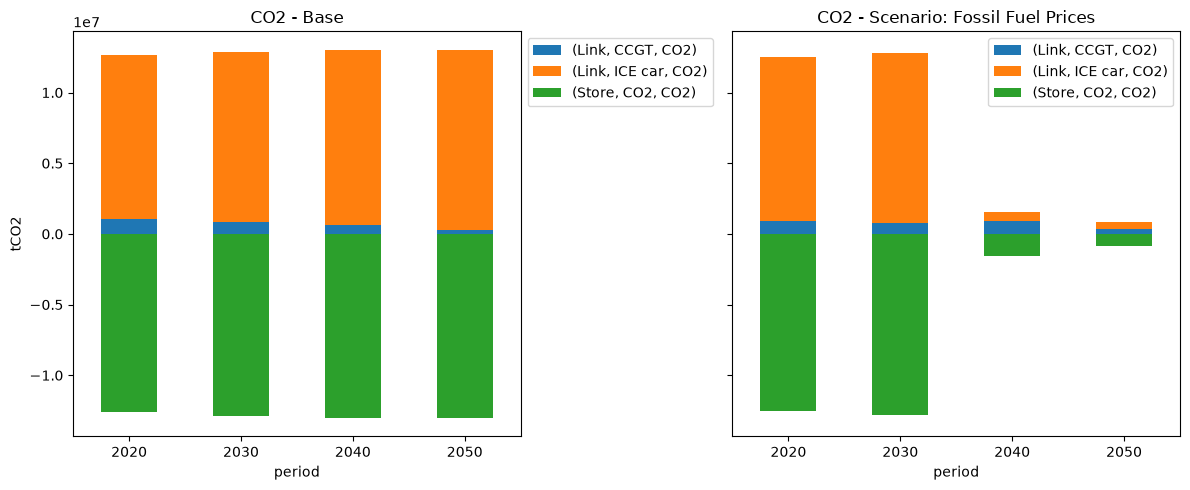

In [8]:
### YOUR CODE HERE ###
# Compare scenarios 
for c in ['Electricity', 'Transportation', 'CO2']:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    for ax, n, name in zip(axes, [base, m_ffprices], ['Base', 'Scenario: Fossil Fuel Prices']):
        n.statistics.energy_balance(bus_carrier=c).T.plot(kind='bar', stacked=True, rot=0, ax=ax)
        ax.set_title(f'{c} - {name}')
        ax.legend(bbox_to_anchor=(1, 1))

        if c == 'CO2':
            ax.set_ylabel('tCO2')
        elif c == 'Transportation':
            ax.set_ylabel('Mvkm')
        else:
            ax.set_ylabel('MWh')

    plt.tight_layout()
    plt.show()
###

### EXPLANATION 2.1 
Compared to the baseline scenario, the scenario with fossil fuel prices tends to make use of 'green' resources more, like wind and solar when it comes electricity production. Along the same lines, transportation in the fossil fuel prices scenario is dominated by electric cars starting from the years 2040, which do not require gasoline, while BEV were virtually not deployed in the baseline scenario. From this follows that the CO2 emissions were greatly reduced in the fossil fuels prices scenario, compared to the baseline. 

This is because adding a price to fossil fuels supply, like gas and gasoline, steer the model to utilize more 'free' resources, such as wind and solar, to minimise the costs of the energy provision. 


## 2.2 CO2 price and limit
1. Create a copy of the *default* database folder, name it *co2price*. Add an increasing CO2 price trajectory between 2020 and 2050 going from 300 to 1000 €/tCO2 and run the model. (We are using very high CO2 prices here just to test and illustrate how the model works).
2. Create a new copy of the *default* database folder, name it *co2cap*. Cap the CO2 budget to 15 MtCO2 from 2030 onwards and run the model.
3. Make a plot to compare the *cumulative* CO2 energy balance in the 4 scenarios you have run so far

In [9]:
### YOUR CODE HERE ###
# Creating the co2 prices scenario
db_dir_3 = 'input_databases/co2price'
m_co2price = model_run(db_dir_3, years,t_res,passenger_cars_cf,rt,rs)
m_co2price.name = 'Model: CO2 prices'
###

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 585.83it/s]

Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31


Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-hi4r9esm.lp
Reading time = 0.18 seconds
obj: 134936 rows, 61352 columns, 272011 nonzeros
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal


In [10]:
### YOUR CODE HERE ###
# Creating the co2 cap scenario 
db_dir_4 = 'input_databases/co2cap'
m_co2cap = model_run(db_dir_4, years,t_res,passenger_cars_cf,rt,rs)
m_co2cap.name = 'Model: CO2 cap'
###

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 553.37it/s]

Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31


Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-_eh4f06g.lp
Reading time = 0.18 seconds
obj: 134936 rows, 61352 columns, 272011 nonzeros
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal


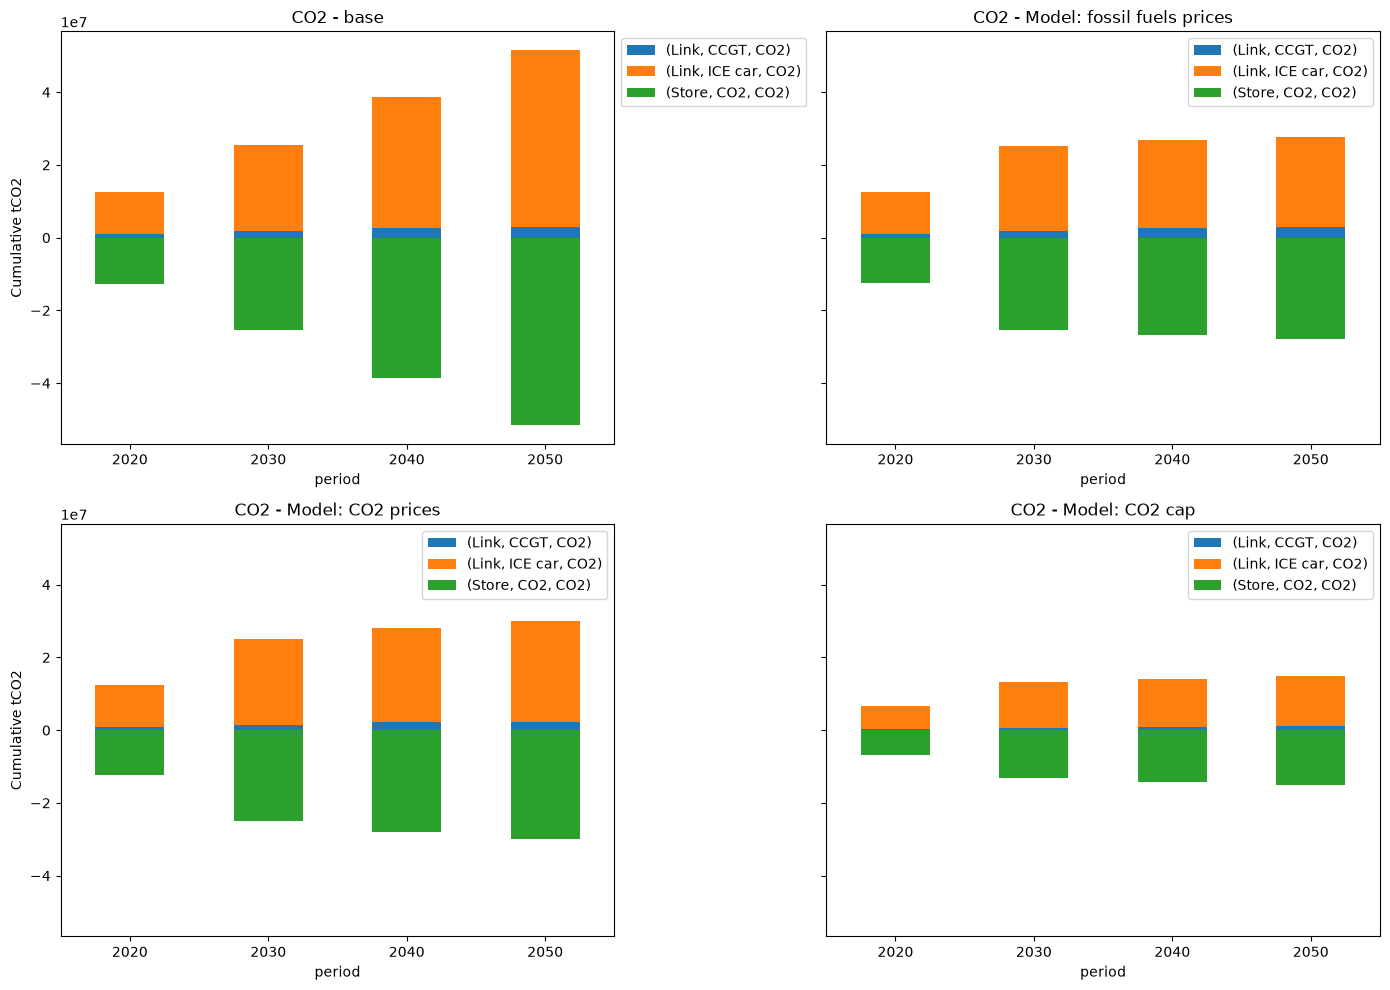

In [11]:
### YOUR CODE HERE ###
# Creating a plot for CO2 energy balance 
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)

for ax, n in zip(axes.flatten(), [base, m_ffprices, m_co2price, m_co2cap]):
    n.statistics.energy_balance(bus_carrier='CO2').T.cumsum().plot(
        kind='bar', stacked=True, rot=0, ax=ax
    )
    ax.set_title(f'CO2 - {n.name}')
    ax.legend(bbox_to_anchor=(1, 1))

axes[0, 0].set_ylabel('Cumulative tCO2')
axes[1, 0].set_ylabel('Cumulative tCO2')

plt.tight_layout()
plt.show()
###

### EXPLANATION 2.2.3
As visible above, the four scenarios present quite different profiles regarding the cumulative CO2 energy balance. The baseline, with no fossil fuel prices, no CO2 prices nor carbon cap, shows the highest cumulative increase over the years of CO2. Meanwhile, the scenarios with fossil fuels prices and CO2 prices reflect similar patters: CO2 is sligthly accumulated over the years, but at much lower amount than the baseline scenario. Finally, the carbon cap scenario present the lowest and slowest CO2 accumulation over the years. 

The baseline has the highest emissions as fossil fuels are free and emissions are unconstrained, so the model keeps using the cheapest options, CCGT and ICE cars. Fossil fuel and CO2 prices make those technologies more expensive, so the model switches partly to BEV and renewables, but it keeps some fossil use where it is still cost-competitive, which gives similar, much lower profiles. The carbon cap gives the lowest accumulation because it is a hard limit that applies whatever the cost, forcing emissions down even where fossil technologies would remain the cheaper choice.


## 2.3 Adding a resource and the corresponding technology
Create another new database called *bio*:
1. Add a new resource called 'Biomass supply' of type Reserves with carrier Biomass 
2. Give it a price of 10 €/MWh_th and cap the available reserves in 2020 to 1000 TWh (leave the other periods empty) 
3. Add a technology called 'Biomass plant' as a link in the power sector, with the following dynamic parameters: 
    - CAPEX	€/kW	1200
    - FOM	€/kW	50
    - VOM	€/kWh	0.2
    - Efficiency		0.6
    - Lifetime	years	30

Run the model and check how (i) optimal capacity and (ii) energy balance have changed for the electricity bus after adding biomass (i.e. make plots to compare optimal capacity and energy balance between the fossil fuel and the bio scenario).

(TIP: To obtain consistent colors when comparing scenarios with different number of technologies, you can define a colors dictionary and call it in the plot function)

In [12]:
### YOUR CODE HERE ###
# Creating the biomass scenario 
db_dir_5 = 'input_databases/bio'
m_bio = model_run(db_dir_5, years,t_res,passenger_cars_cf,rt,rs)
m_bio.name = 'Model: with Biomass'
###

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 508.93it/s]

Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31


Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-6j6pqcx3.lp
Reading time = 0.21 seconds
obj: 154796 rows, 71284 columns, 312310 nonzeros
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal


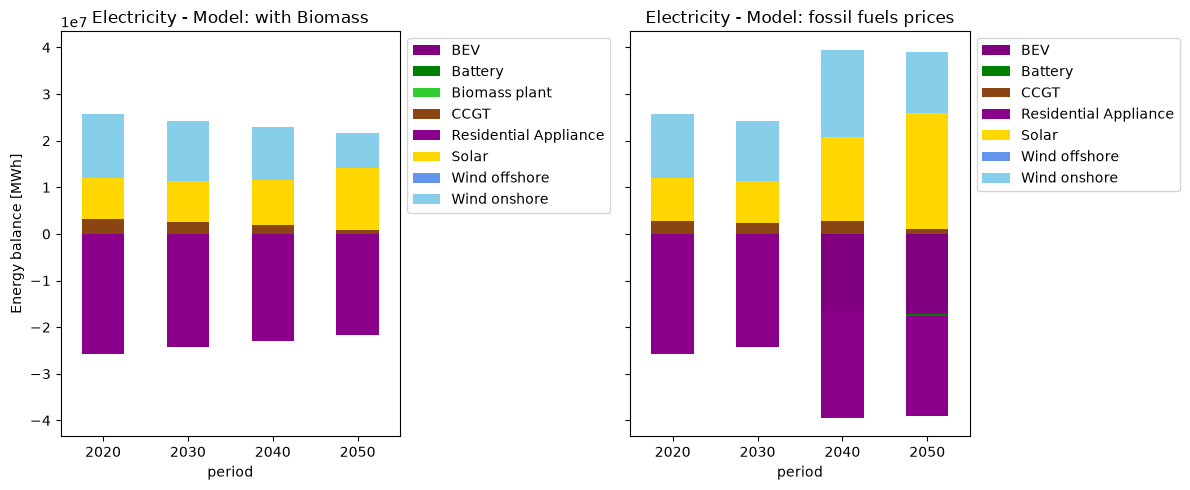

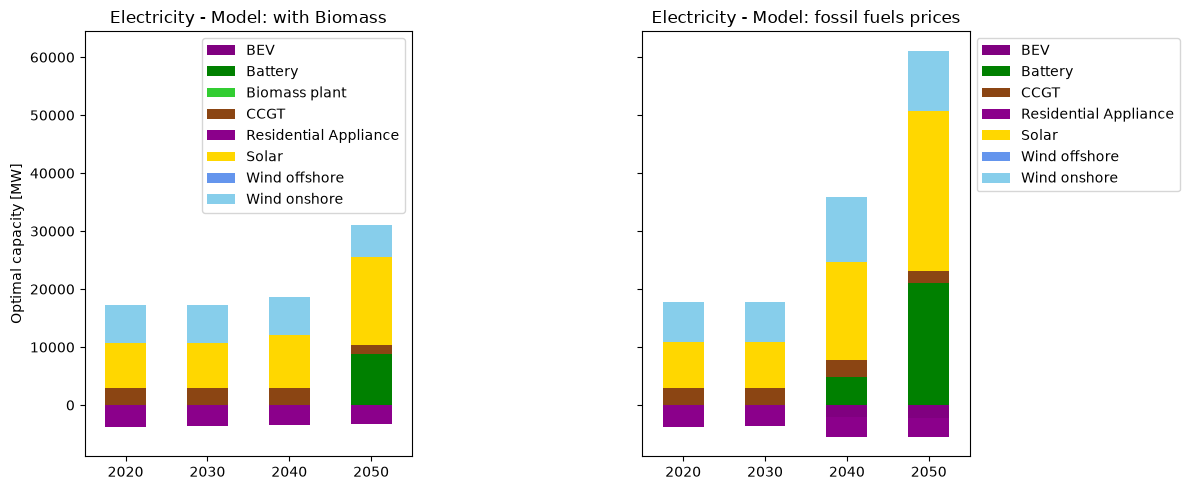

In [13]:
### YOUR CODE HERE ###

colors = {
    'CCGT': 'saddlebrown',
    'Solar': 'gold',
    'Wind onshore': 'skyblue',
    'Wind offshore': 'cornflowerblue',
    'Battery': 'green',
    'Biomass plant': 'limegreen',       
    'BEV': 'purple',
    'Residential Appliance': 'darkmagenta',
}


# Creating plots to compare energy balance for electricity bus between fossil fuel and biomass scenarios 

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, n in zip(axes.flatten(), [m_bio, m_ffprices]):
    n.statistics.energy_balance(bus_carrier='Electricity').groupby('carrier').sum().T.plot(
        kind='bar', stacked=True, rot=0, ax=ax, color=colors
    )
    ax.set_title(f'Electricity - {n.name}')
    ax.legend(bbox_to_anchor=(1, 1))

axes[0].set_ylabel('Energy balance [MWh]')

plt.tight_layout()
plt.show()

# Creating plots to compare optimal capacity for electricity bus between fossil fuel and biomass scenarios
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, n in zip(axes.flatten(), [m_bio, m_ffprices]):
    n.statistics.optimal_capacity(bus_carrier='Electricity').groupby('carrier').sum().T.plot(
        kind='bar', stacked=True, rot=0, ax=ax, color=colors
    )
    ax.set_title(f'Electricity - {n.name}')
    ax.legend(bbox_to_anchor=(1, 1))

axes[0].set_ylabel('Optimal capacity [MW]')

plt.tight_layout()
plt.show()
###
